# Создание нейронной сети на Torch

In [5]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline


## Нейрон

<img src="img/neuron.png" width=300, heigth=300>

In [6]:
# Создание класса нейрон. weights - веса связей, bias - порог, input - вектор сигналов, подающихся на нейрон

class Neuron:
  def __init__(self, weights, bias):
    self.weights = weights
    self.bias = bias
  
  def forward(self, input):
    return torch.dot(self.weights, input) + self.bias # dot - скалярное произведение векторов

In [7]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])

weights = torch.tensor([0.2, 0.8, -0.5, 1.0])
bias = 2.0

neuron = Neuron(weights, bias)
neuron.forward(inputs)

tensor(4.8000)

## Слой

In [8]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases
  
  def forward(self, input):
    return torch.mv(self.weights, input) + self.biases #mv - произведение вектора на матрицу

In [9]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])
weights = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])

biases = torch.tensor([2.0, 3.0, 0.5])

layer = Layer(weights, biases)
layer.forward(inputs)

tensor([4.8000, 1.2100, 2.3850])

## Слой (batch)
обработка партиями

In [10]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases
  
  def forward(self, inputs):
    return inputs @ self.weights.T + self.biases # провизведение матриц

In [11]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
weights1 = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])
biases1 = torch.tensor([2.0, 3.0, 0.5])

weights2 = torch.tensor([[.1, -.14, .5], [-.5, .12, -.33], [-.44, .73, -.13]])
biases2 = torch.tensor([-1, 2, -.5])

layer1 = Layer(weights1, biases1)
hidden_input = layer1.forward(inputs1)

layer2 = Layer(weights2, biases2)
output = layer2.forward(hidden_input)
output

tensor([[ 0.5031, -1.0419, -2.0388],
        [ 0.2434, -2.7332, -5.7633],
        [-0.9931,  1.4125, -0.3565]])

## Слой (случ. иниц)

In [12]:
class Layer:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons)
    self.biases = torch.zeros(n_neurons)
  
  def forward(self, inputs):
    return inputs @ self.weights + self.biases

In [13]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 6)
out = layer.forward(inputs1)
out

tensor([[ 9.5091e-01,  3.6636e-01, -3.3173e+00,  6.3487e+00, -2.5678e+00,
         -2.7820e+00],
        [-5.2975e-01, -1.9087e+00, -4.5252e+00,  1.0733e+01, -8.8817e-03,
         -1.4838e+00],
        [-4.3074e-01, -1.9555e+00, -5.3848e-01,  5.1126e+00, -3.9243e+00,
         -2.1512e+00]])

## Функции активации

<img src="img/Act.png" width=500, heigth=300>

Функция активации ReLU:
![](https://wikimedia.org/api/rest_v1/media/math/render/svg/f4353f4e3e484130504049599d2e7b040793e1eb)
Функцию активации softmax:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/6d7500d980c313da83e4117da701bf7c8f1982f5)

In [14]:
# RELU
class ReLU:
  def forward(self, inputs):
    return inputs.clip(min=0)    # заменить отрицательные числа нулями

In [15]:
ReLU().forward(out)

tensor([[ 0.9509,  0.3664,  0.0000,  6.3487,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000, 10.7330,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  5.1126,  0.0000,  0.0000]])

In [16]:
class Softmax:
  def forward(self, inputs):
    exp = torch.exp(inputs)
    probs = exp / exp.sum(dim=1, keepdim=True)
    return probs 

In [17]:
Softmax().forward(out)

tensor([[4.4937e-03, 2.5046e-03, 6.2942e-05, 9.9270e-01, 1.3319e-04, 1.0750e-04],
        [1.2842e-05, 3.2343e-06, 2.3629e-07, 9.9996e-01, 2.1620e-05, 4.9465e-06],
        [3.8780e-03, 8.4415e-04, 3.4819e-03, 9.9098e-01, 1.1786e-04, 6.9407e-04]])

## Функции потерь

Функция потерь MSE:

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/e258221518869aa1c6561bb75b99476c4734108e)
Функция потерь Categorical Cross-Entropy:

<img src="https://i.ibb.co/93gy1dN/Screenshot-9.png" width="200">


In [18]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 1)
out = layer.forward(inputs1)
out

tensor([[10.7715],
        [ 7.5704],
        [10.7167]])

In [19]:
# Среднеквадратичная ошибка
class MSELoss:
  def forward(self, y_pred, y_true):
    return torch.mean(torch.pow(out - y_true, 2))

In [20]:
y_true = torch.tensor([2, 3, 4]).view(-1, 1)
MSELoss().forward(out, y_true)

tensor(47.6473)

In [21]:
# Кроссэнтропия
class CategoricalCrossentropyLoss:
  def forward(self, y_pred, y_true):
    correct_conf = y_pred.gather(dim=1, index=y_true.view(-1, 1))
    neglog = -torch.log(correct_conf)
    return torch.mean(neglog)

In [22]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 3)
out = layer.forward(inputs1)
out = Softmax().forward(out)
out

tensor([[6.5256e-05, 2.8558e-03, 9.9708e-01],
        [1.1214e-02, 9.7727e-01, 1.1517e-02],
        [1.4168e-06, 2.9832e-03, 9.9702e-01]])

In [23]:
y_true = torch.tensor([1, 0, 0])
CategoricalCrossentropyLoss().forward(out, y_true)

tensor(7.9387)

## Оптимизация SGD (стохастический градиентный спуск)

#### Модифицируем класс Neuron
    Сделаем так, чтобы веса нейрона инициализировались из стандартного нормального распределения:

In [24]:
# Сформируем случайную задачу регркессии
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

Граф вычислений для решения задачи:
<img src="img/back.png" width=700, heigth=700>

In [25]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs)
    self.bias = torch.randn(1)
  
  def forward(self, input):
    self.input = input
    return torch.dot(self.weights, input) + self.bias

  def backward(self, dvalue):
    self.dweights = dvalue * self.input
    self.dinput = dvalue * self.weights
    self.dbias = dvalue


class Loss:    #класс вычисления ошибок
  def forward(self, y_pred, y_true):
    return (y_pred - y_true) ** 2

  def backward(self, y_pred, y_true):
    self.dinput = 2 * (y_pred - y_true)


In [26]:
neuron = Neuron(4)
loss = Loss()

lr = 0.1

losses = []
for epoch in range(100):
  for x_example, y_example in zip(X, y):
    y_pred = neuron.forward(x_example)
    l = loss.forward(y_pred, y_example)
    losses.append(l)

    loss.backward(y_pred, y_example)
    neuron.backward(loss.dinput)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbias
  

In [27]:
neuron.weights, neuron.bias

(tensor([ 6.0160, 74.7099, 74.0140, 89.2026]), tensor([0.5000]))

#### Используем пакетный градиентный спуск (batch SGD + neuron)

In [28]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs, requires_grad=False)
    self.bias = torch.tensor(0.0, requires_grad=False)
  
  def forward(self, inputs):
    self.inputs = inputs
    return X @ self.weights.T + self.bias

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T.mv(dvalues)
      self.dbiases = dvalues.sum()


class MSELossNeuron:
  def forward(self, y_pred, y_true):
    return torch.mean((y_pred - y_true) ** 2)

  def backward(self, y_pred, y_true):
    with torch.no_grad():
      self.dinputs = 2 * (y_pred - y_true) / len(y_pred)

Вычисления для решения задачи:
    <img src="img/back1.png" width=700, heigth=700>
    <img src="img/back2.png" width=700, heigth=700>

In [29]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

In [30]:
neuron = Neuron(4)
loss = MSELossNeuron()

lr = 0.1

for epoch in range(100):
    y_pred = neuron.forward(X)
    l = loss.forward(y_pred, y)
    loss.backward(y_pred, y)
    neuron.backward(loss.dinputs)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbiases
print(f'epoch {epoch} mean loss {l.mean()}')

epoch 99 mean loss 6.3099220293239e-10


C:\Users\valentin\AppData\Local\Temp\ipykernel_14300\2213006203.py:8: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4323.)
  return X @ self.weights.T + self.bias


In [31]:
neuron.weights, coef

(tensor([16.9170, 63.5871, 85.4234, 91.2807]),
 array([16.91698424, 63.587105  , 85.42338073, 91.28073651]))

### Разные варианты веализации рейросети

In [32]:
class Dense:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons, requires_grad=False)
    self.biases = torch.zeros(n_neurons, requires_grad=False)
  
  def forward(self, inputs):
    self.inputs = inputs
    self.output = self.inputs @ self.weights + self.biases
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T @ dvalues
      self.dbiases = torch.sum(dvalues, dim=0)
      self.dinputs = dvalues @ self.weights.T

class Activation_ReLU:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs.clip(min=0)
    return self.output
  
  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()
      self.dinputs[self.inputs <= 0] = 0

class Activation_Linear:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()

class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = sample_losses.mean()
    return data_loss

class MSELoss(Loss):
  def forward(self, y_pred, y_true):
    sample_losses = torch.mean((y_true - y_pred) ** 2, dim=1)
    return sample_losses

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      self.dinputs = -2 * (y_true - dvalues) / len(dvalues)


In [33]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [34]:
fc1 = Dense(4, 1)
loss = MSELoss()
lr = 0.1

for epoch in range(100):
  out = fc1.forward(X)
  data_loss = loss.calculate(out, y.view(-1, 1))
  print(f'epoch {epoch} mean loss {data_loss}')
  loss.backward(out, y.view(-1, 1))
  fc1.backward(loss.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

epoch 0 mean loss 24506.205078125
epoch 1 mean loss 15329.6279296875
epoch 2 mean loss 9638.7490234375
epoch 3 mean loss 6094.11767578125
epoch 4 mean loss 3875.77587890625
epoch 5 mean loss 2480.301025390625
epoch 6 mean loss 1597.5899658203125
epoch 7 mean loss 1035.9312744140625
epoch 8 mean loss 676.3295288085938
epoch 9 mean loss 444.5987548828125
epoch 10 mean loss 294.2694091796875
epoch 11 mean loss 196.0814971923828
epoch 12 mean loss 131.50965881347656
epoch 13 mean loss 88.75457763671875
epoch 14 mean loss 60.255455017089844
epoch 15 mean loss 41.13516616821289
epoch 16 mean loss 28.227338790893555
epoch 17 mean loss 19.4619140625
epoch 18 mean loss 13.476587295532227
epoch 19 mean loss 9.368518829345703
epoch 20 mean loss 6.5356550216674805
epoch 21 mean loss 4.57373046875
epoch 22 mean loss 3.20967435836792
epoch 23 mean loss 2.257991075515747
epoch 24 mean loss 1.5919444561004639
epoch 25 mean loss 1.1244882345199585
epoch 26 mean loss 0.7956178188323975
epoch 27 mean los

In [35]:
fc1.weights, coef

(tensor([[94.7740],
         [71.6697],
         [32.3103],
         [92.9566]]),
 array([94.77405482, 71.66968521, 32.31033527, 92.95662768]))

In [36]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [37]:
X = torch.linspace(-1, 1, 100).view(-1, 1)
y = X.pow(2) + 0.2 * torch.rand(X.size()) 

In [38]:
fc1 = Dense(1, 10)
relu1 = Activation_ReLU()
fc2 = Dense(10, 1)

loss = MSELoss()
lr = 0.02

ys = []
for epoch in range(2001):
  out = fc1.forward(X)
  out = relu1.forward(out)
  out = fc2.forward(out)


  data_loss = loss.calculate(out, y)
  if epoch % 200 == 0:
    print(f'epoch {epoch} mean loss {data_loss}')
    ys.append(out)
  loss.backward(out, y)
  fc2.backward(loss.dinputs)
  relu1.backward(fc2.dinputs)
  fc1.backward(relu1.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

  fc2.weights -= lr * fc2.dweights
  fc2.biases -= lr * fc2.dbiases 

epoch 0 mean loss 3.2902588844299316
epoch 200 mean loss 0.01054325420409441
epoch 400 mean loss 0.006423642858862877
epoch 600 mean loss 0.005297929048538208
epoch 800 mean loss 0.004834996070712805
epoch 1000 mean loss 0.004526957869529724
epoch 1200 mean loss 0.004318791441619396
epoch 1400 mean loss 0.004174151923507452
epoch 1600 mean loss 0.004089234862476587
epoch 1800 mean loss 0.004013244993984699
epoch 2000 mean loss 0.0039534904062747955


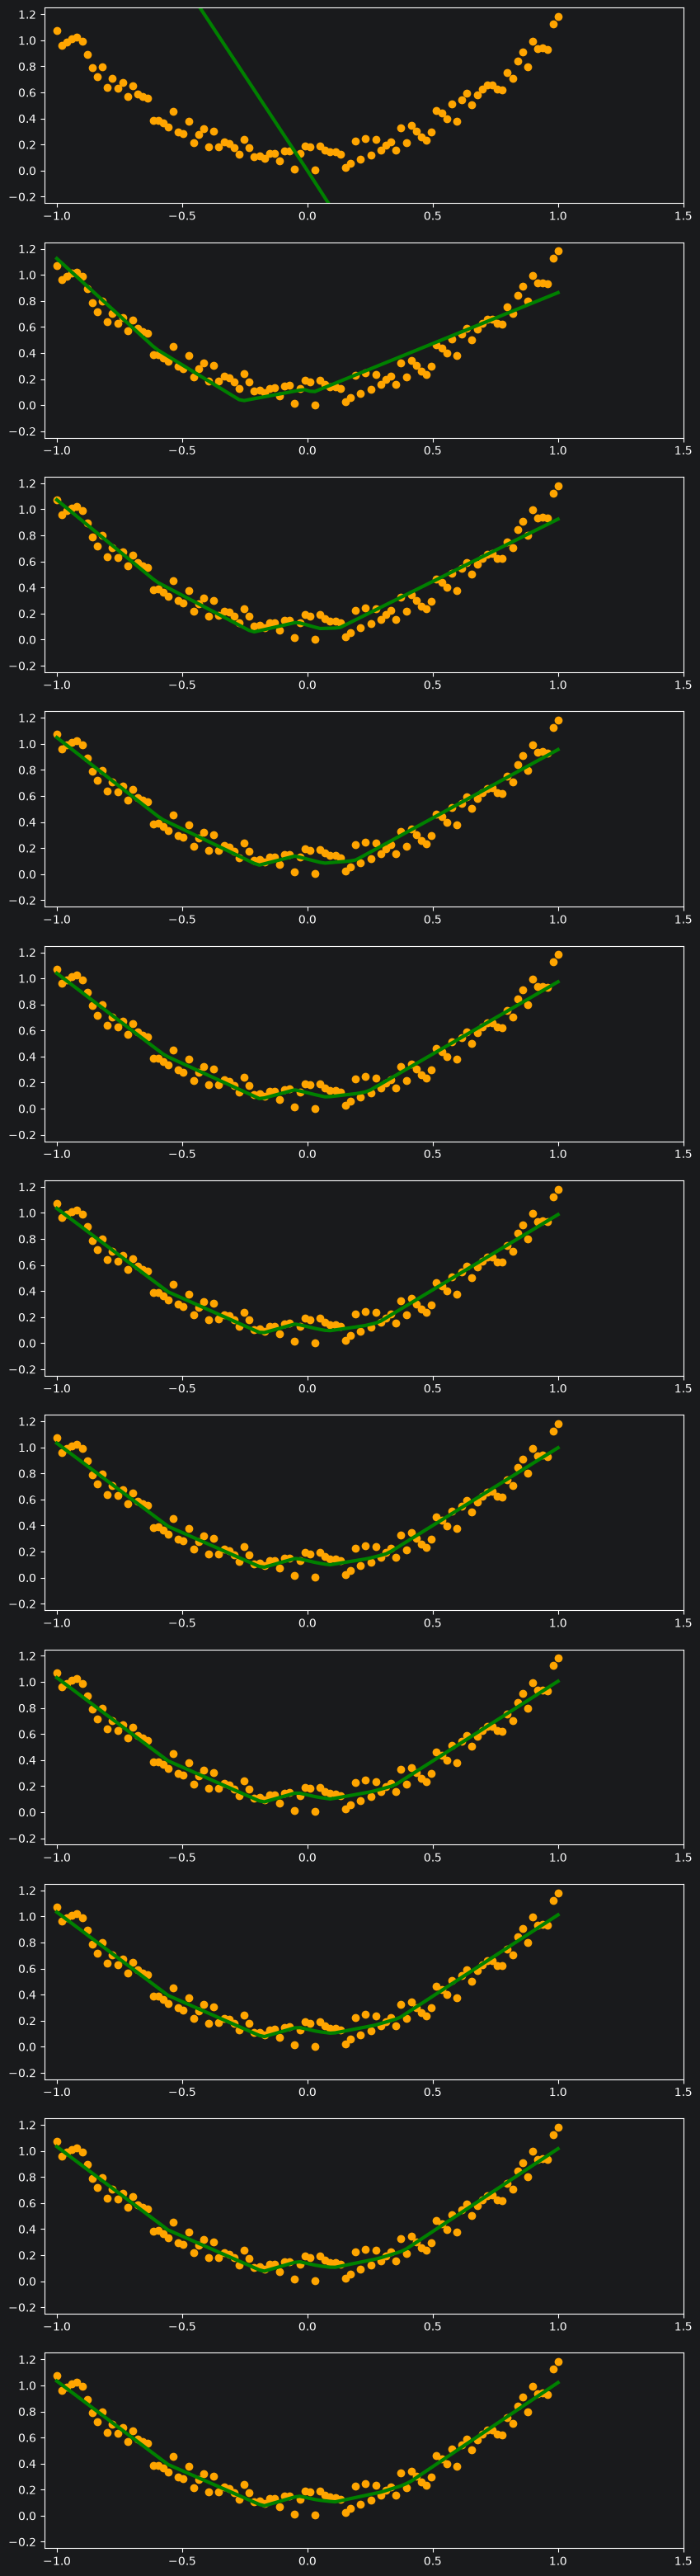

In [39]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(ys), 1, figsize=(10, 40))
for ax, y_ in zip(axs, ys):
  ax.scatter(X.numpy(), y.numpy(), color = "orange")
  ax.plot(X.numpy(), y_.numpy(), 'g-', lw=3)
  ax.set_xlim(-1.05, 1.5)
  ax.set_ylim(-0.25, 1.25)

## Датасет - Bank Marketing (UCI)

In [1]:
import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

df = pd.read_csv("bank-full.csv", sep=';')
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## EDA (Разведочный анализ данных)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


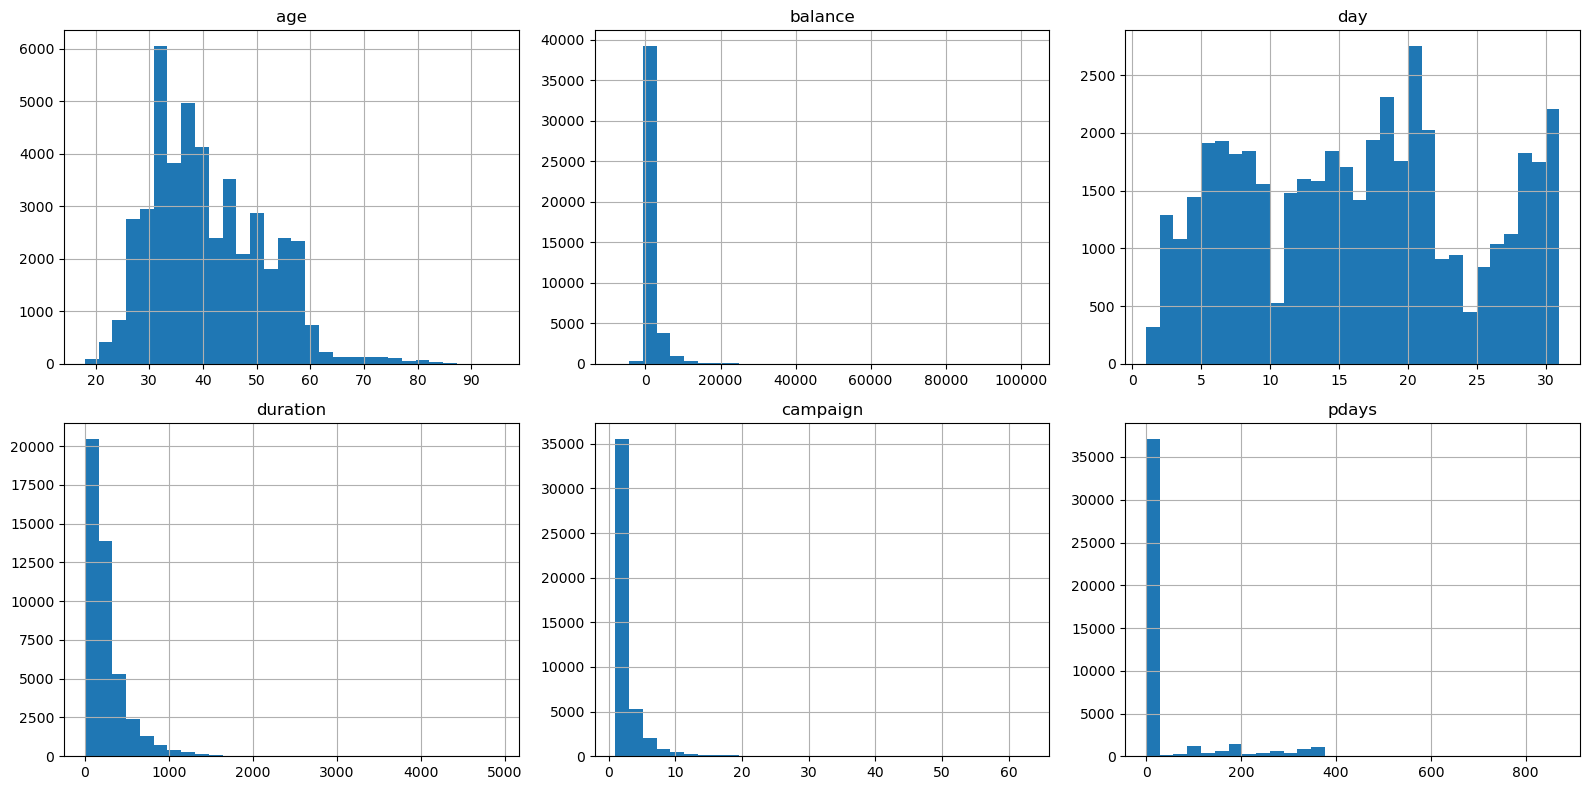

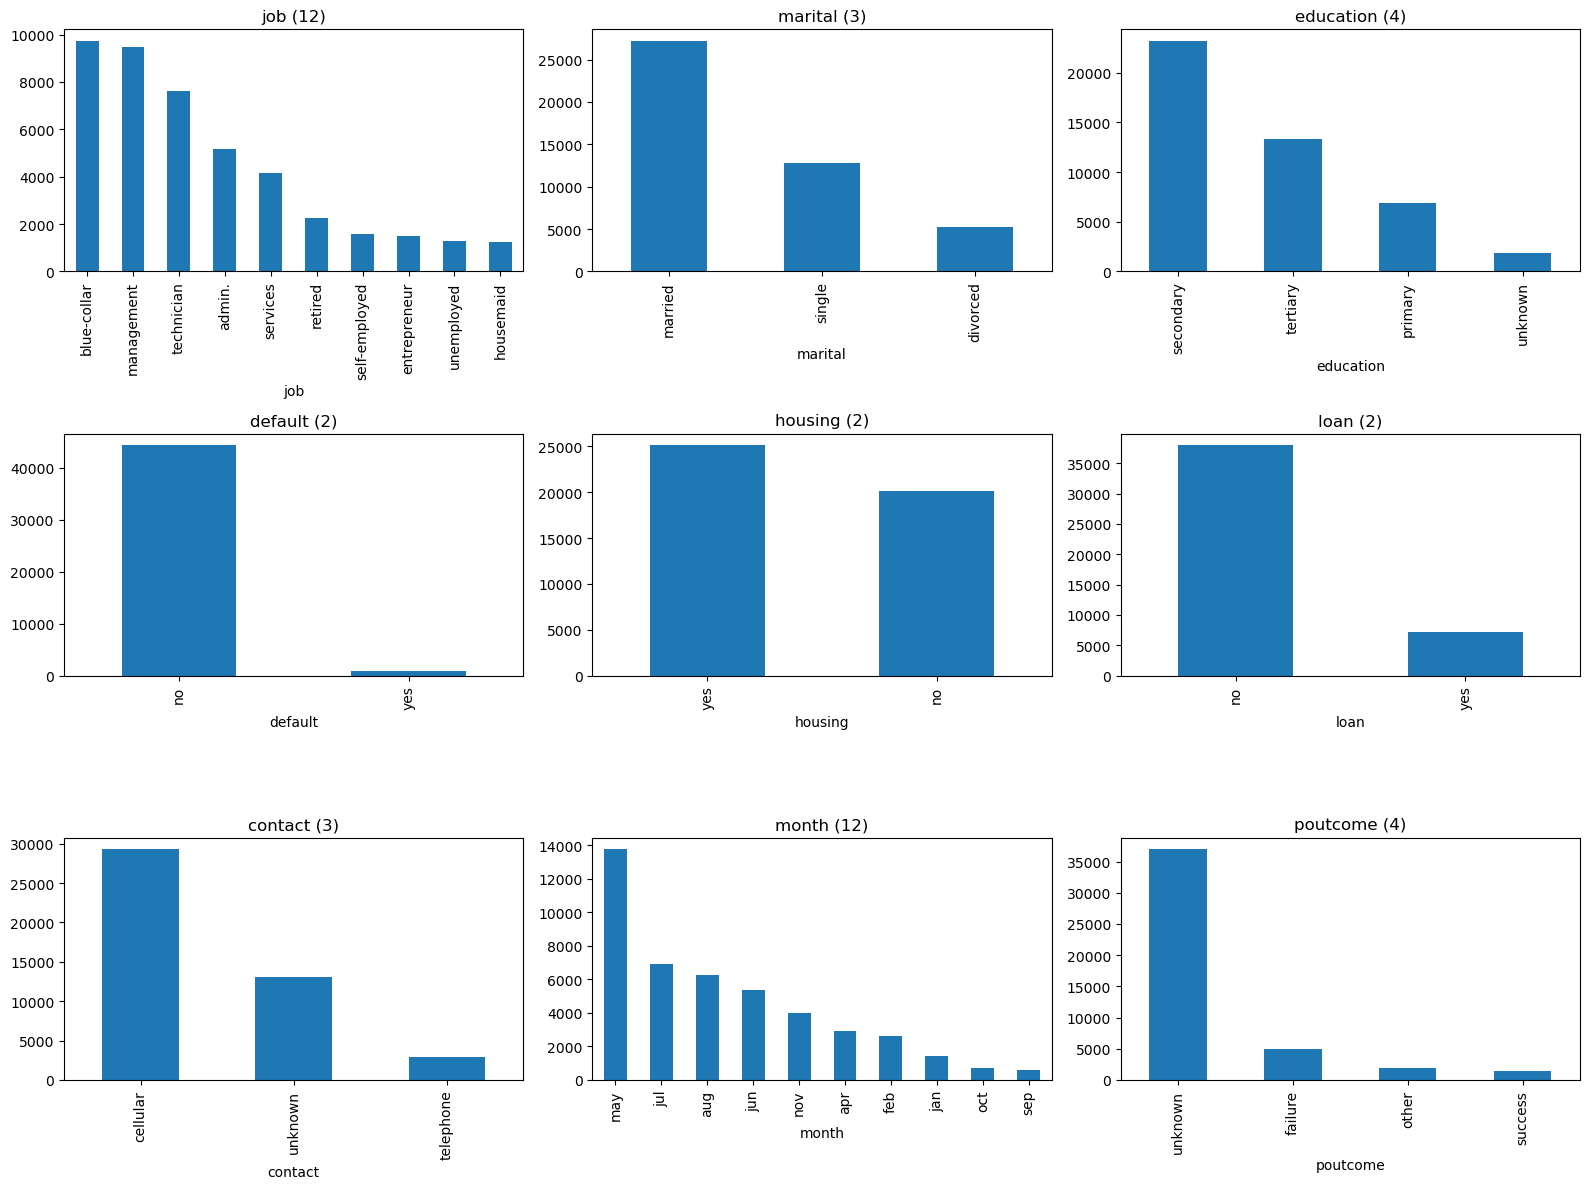

In [2]:
df.info()
df.describe()
print(df['y'].value_counts(normalize=True))

num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns.drop('y')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    df[c].hist(ax=ax, bins=30)
    ax.set_title(c)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, c in zip(axes.ravel(), cat_cols):
    df[c].value_counts().head(10).plot(kind='bar', ax=ax)
    ax.set_title(f'{c} ({df[c].nunique()})')
plt.tight_layout(); plt.show()

## Препроцессинг данных

In [3]:
target = 'y'
df[target] = (df[target] == 'yes').astype(int)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop(target)
cat_cols = df.select_dtypes(include=['object']).columns

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[target], random_state=42)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
pipe = Pipeline([('pre', preprocessor)])

X_train = torch.tensor(pipe.fit_transform(train_df), dtype=torch.float32)
X_test  = torch.tensor(pipe.transform(test_df), dtype=torch.float32)
y_train = torch.tensor(train_df[target].values, dtype=torch.float32).view(-1, 1)
y_test  = torch.tensor(test_df[target].values, dtype=torch.float32).view(-1, 1)
X_train.shape, X_test.shape

(torch.Size([36168, 51]), torch.Size([9043, 51]))

## Архитектура нейронной сети

In [6]:
class Dense:
    def __init__(self, n_in, n_out):
        self.weights = torch.randn(n_in, n_out) * (2 / n_in) ** 0.5
        self.biases = torch.zeros(n_out)
    def forward(self, x):
        self.inputs = x
        return x @ self.weights + self.biases
    def backward(self, d):
        with torch.no_grad():
            self.dweights = self.inputs.T @ d
            self.dbiases = d.sum(0)
            self.dinputs = d @ self.weights.T

class ReLU:
    def forward(self, x):
        self.inputs = x
        return x.clip(min=0)
    def backward(self, d):
        with torch.no_grad():
            self.dinputs = d.clone()
            self.dinputs[self.inputs <= 0] = 0

class BCEWithLogits:
    def forward(self, logits, y):
        return (torch.clamp(logits, min=0) - logits * y + torch.log1p(torch.exp(-logits.abs()))).mean()
    def backward(self, logits, y):
        with torch.no_grad():
            self.dinputs = (torch.sigmoid(logits) - y) / len(y)

class MLP:
    def __init__(self, n_in, h1, h2):
        self.fc1, self.relu1 = Dense(n_in, h1), ReLU()
        self.fc2, self.relu2 = Dense(h1, h2), ReLU()
        self.fc3 = Dense(h2, 1)
    def forward(self, x):
        return self.fc3.forward(self.relu2.forward(self.fc2.forward(self.relu1.forward(self.fc1.forward(x)))))
    def backward(self, d):
        self.fc3.backward(d)
        self.relu2.backward(self.fc3.dinputs)
        self.fc2.backward(self.relu2.dinputs)
        self.relu1.backward(self.fc2.dinputs)
        self.fc1.backward(self.relu1.dinputs)
    def step(self, lr):
        for fc in (self.fc1, self.fc2, self.fc3):
            fc.weights -= lr * fc.dweights
            fc.biases  -= lr * fc.dbiases
    def predict_proba(self, x):
        return torch.sigmoid(self.forward(x))

## Обучение модели

In [22]:
model = MLP(X_train.shape[1], 128, 64)
loss_fn = BCEWithLogits()
lr, bs, epochs = 0.001, 4096, 100 

for epoch in range(epochs):
    perm = torch.randperm(len(X_train))
    total = 0.0
    for i in range(0, len(X_train), bs):
        idx = perm[i:i+bs]
        xb, yb = X_train[idx], y_train[idx]
        
        out = model.forward(xb)
        loss = loss_fn.forward(out, yb)
        total += loss.item() * len(idx)
        
        loss_fn.backward(out, yb)
        model.backward(loss_fn.dinputs)
        model.step(lr)
        
    if epoch % 20 == 0:
        print(f'epoch {epoch} loss {total/len(X_train):.4f}')

epoch 0 loss 0.6759
epoch 20 loss 0.3758
epoch 40 loss 0.3404
epoch 60 loss 0.3286
epoch 80 loss 0.3210


## Оценка качества модели (Метрики)

In [23]:
proba = model.predict_proba(X_test).view(-1).numpy()
pred  = (proba >= 0.3).astype(int) 
true  = y_test.view(-1).numpy()

print('precision', precision_score(true, pred))
print('recall   ', recall_score(true, pred))
print('f1       ', f1_score(true, pred))
print('roc-auc  ', roc_auc_score(true, proba))

precision 0.46488294314381273
recall    0.13137996219281664
f1        0.20486366985998525
roc-auc   0.7751803653589611
